In [12]:
import pandas as pd
import numpy as np

In [27]:
df = pd.read_csv(r"C:\Users\zubai\OneDrive\Desktop\Project\Airline_performance.csv")
df.head(10)   # Preview neatly


,No,Flight,Date,Passengers,Revenue,Route
0,1,AI201,15-01-2026,180.0,45000,DEL-BOM
1,2,AI202,20-01-2026,200.0,50000,DEL-MAA
2,3,AI203,05-02-2026,220.0,60000,BOM-MAA
3,4,AI204,10-02-2026,NaN,55000,DEL-BLR
4,5,AI205,01-03-2026,190.0,48000,MAA-BLR
5,6,AI206,15-03-2026,210.0,62000,DEL-BOM
6,7,AI207,01-04-2026,230.0,70000,DEL-MAA
7,8,AI208,10-04-2026,250.0,75000,BOM-MAA
8,9,AI209,05-05-2026,240.0,68000,DEL-BLR
9,10,AI210,20-05-2026,260.0,80000,MAA-BLR


In [28]:

# To find null values in the dataset
df.isnull().sum()

No            0
Flight        0
Date          0
Passengers    1
Revenue       0
Route         0
dtype: int64

In [29]:
df.fillna({"Passengers": 0}, inplace=True)

# To change the NAN values in the dataset to 0

,No,Flight,Date,Passengers,Revenue,Route
0,1,AI201,15-01-2026,180.0,45000,DEL-BOM
1,2,AI202,20-01-2026,200.0,50000,DEL-MAA
2,3,AI203,05-02-2026,220.0,60000,BOM-MAA
3,4,AI204,10-02-2026,0.0,55000,DEL-BLR
4,5,AI205,01-03-2026,190.0,48000,MAA-BLR
5,6,AI206,15-03-2026,210.0,62000,DEL-BOM
6,7,AI207,01-04-2026,230.0,70000,DEL-MAA
7,8,AI208,10-04-2026,250.0,75000,BOM-MAA
8,9,AI209,05-05-2026,240.0,68000,DEL-BLR
9,10,AI210,20-05-2026,260.0,80000,MAA-BLR


In [30]:
df.isnull().sum()

# To recheck the null values in the dataset after changing NAN values to 0

No            0
Flight        0
Date          0
Passengers    0
Revenue       0
Route         0
dtype: int64

In [ ]:
df.dtypes

# To check the data types of each column in the dataset

No                     int64
Flight                   str
Date          datetime64[us]
Passengers           float64
Revenue                int64
Route                    str
dtype: object

In [ ]:
# df.groupby(df["Date"].dt.month)["Revenue"].sum()

# To group the data by month and calculate the total revenue for each month

Date
1     95000
2    115000
3    110000
4    145000
5    148000
Name: Revenue, dtype: int64

In [86]:
route_perf = df.groupby("Route")[["Passengers","Revenue"]].sum()
route_perf


,Passengers,Revenue
Route,,
BOM-MAA,470.0,135000
DEL-BLR,240.0,123000
DEL-BOM,390.0,107000
DEL-MAA,430.0,120000
MAA-BLR,450.0,128000


In [36]:
# Group by month number (1 = Jan, 2 = Feb, etc.)
monthly_revenue = df.groupby(df["Date"].dt.month)["Revenue"].sum()
print(monthly_revenue)


Date
1     95000
2    115000
3    110000
4    145000
5    148000
Name: Revenue, dtype: int64


In [ ]:
monthly_revenue = df.groupby(df["Date"].dt.strftime("%B"))["Revenue"].sum()
print(monthly_revenue)

# strftime("%B") is used to extract the month name from the "Date" column in the DataFrame. 
# It formats the date as a string representing the full month name (e.g., "January", "February", etc.). 
# to avoid confusion with month numbers and to make the output more user-friendly.
# This allows for grouping the data by month names instead of just month numbers, making the output more readable and understandable.

# "%B" is a format code used in the strftime function to represent the full month name.



Date
April       145000
February    115000
January      95000
March       110000
May         148000
Name: Revenue, dtype: int64


In [44]:
df.pivot_table(index=df["Date"].dt.month, values="Revenue", aggfunc="sum")

# index meaning: The index parameter specifies the column or columns to group by in the pivot table. 
# In this case, it's grouping by the month number extracted from the "Date" column.


,Revenue
Date,
1,95000
2,115000
3,110000
4,145000
5,148000


In [ ]:
# Month numbers Ex 1
df.groupby(df["Date"].dt.month)["Revenue"].sum()



Date
Apr    145000
Feb    115000
Jan     95000
Mar    110000
May    148000
Name: Revenue, dtype: int64

In [ ]:
df.groupby(df["Date"].dt.strftime("%b"))["Revenue"].sum()

# Short month names Ex 2

Date
Apr    145000
Feb    115000
Jan     95000
Mar    110000
May    148000
Name: Revenue, dtype: int64

In [48]:
monthly_revenue = df.groupby(df["Date"].dt.strftime("%B"))["Revenue"].sum()
print(monthly_revenue.sort_values(ascending=True))

# Ex 3: Full month names sorted in ascending order of revenue

Date
January      95000
March       110000
February    115000
April       145000
May         148000
Name: Revenue, dtype: int64


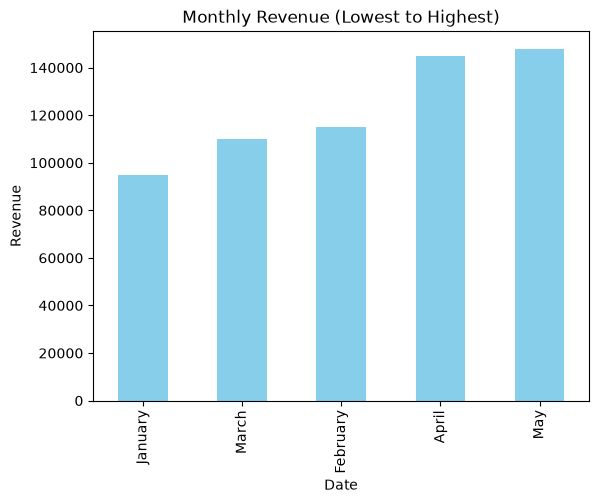

In [49]:
import matplotlib.pyplot as plt

monthly_revenue.sort_values(ascending=True).plot(kind="bar", color="skyblue")
plt.title("Monthly Revenue (Lowest to Highest)")
plt.ylabel("Revenue")
plt.show()


In [50]:
df[df["Date"].dt.month == 1][["Date", "Revenue"]]


,Date,Revenue
0,2026-01-15,45000
1,2026-01-20,50000


In [54]:
monthly_revenue = df.groupby([df["Date"].dt.year, df["Date"].dt.month])["Revenue"].sum()
print(monthly_revenue)


Date  Date
2026  1        95000
      2       115000
      3       110000
      4       145000
      5       148000
Name: Revenue, dtype: int64


In [57]:
df["YearMonth"] = df["Date"].dt.strftime("%Y-%b")

monthly_revenue = df.groupby("YearMonth")["Revenue"].sum()
print(monthly_revenue.sort_values(ascending=True))

# combine year and month into a single column called "YearMonth" using the strftime function.
# no confusion with year  2026 & 2027, as the month name is included in the "YearMonth" column.


YearMonth
2026-Jan     95000
2026-Mar    110000
2026-Feb    115000
2026-Apr    145000
2026-May    148000
Name: Revenue, dtype: int64


In [55]:
quarterly_revenue = df.groupby([df["Date"].dt.year, df["Date"].dt.quarter])["Revenue"].sum()
print(quarterly_revenue)

Date  Date
2026  1       320000
      2       293000
Name: Revenue, dtype: int64


In [81]:
quarterly_revenue = df.set_index("Date").resample("QE")["Revenue"].sum()
quarterly_revenue


Date
2026-03-31    320000
2026-06-30    293000
Freq: QE-DEC, Name: Revenue, dtype: int64

In [59]:
df["Revenue_per_Passenger"] = df["Revenue"] / df["Passengers"].replace(0, np.nan)
df.head(10)


,No,Flight,Date,Passengers,Revenue,Route,YearMonth,Revenue_per_Passenger
0,1,AI201,2026-01-15,180.0,45000,DEL-BOM,2026-Jan,250.000000
1,2,AI202,2026-01-20,200.0,50000,DEL-MAA,2026-Jan,250.000000
2,3,AI203,2026-02-05,220.0,60000,BOM-MAA,2026-Feb,272.727273
3,4,AI204,2026-02-10,0.0,55000,DEL-BLR,2026-Feb,NaN
4,5,AI205,2026-03-01,190.0,48000,MAA-BLR,2026-Mar,252.631579
5,6,AI206,2026-03-15,210.0,62000,DEL-BOM,2026-Mar,295.238095
6,7,AI207,2026-04-01,230.0,70000,DEL-MAA,2026-Apr,304.347826
7,8,AI208,2026-04-10,250.0,75000,BOM-MAA,2026-Apr,300.000000
8,9,AI209,2026-05-05,240.0,68000,DEL-BLR,2026-May,283.333333
9,10,AI210,2026-05-20,260.0,80000,MAA-BLR,2026-May,307.692308


In [60]:
summary = {
    "Total Passengers": df["Passengers"].sum(),
    "Total Revenue": df["Revenue"].sum(),
    "Avg Revenue per Passenger": df["Revenue_per_Passenger"].mean()
}
summary


{'Total Passengers': np.float64(1980.0),
 'Total Revenue': np.int64(613000),
 'Avg Revenue per Passenger': np.float64(279.5522682250371)}

In [63]:
summary = {
    "Total Passengers": int(df["Passengers"].sum()),
    "Total Revenue": int(df["Revenue"].sum()),
    "Avg Revenue per Passenger": round(float(df["Revenue_per_Passenger"].mean()), 2)
}
summary



{'Total Passengers': 1980,
 'Total Revenue': 613000,
 'Avg Revenue per Passenger': 279.55}

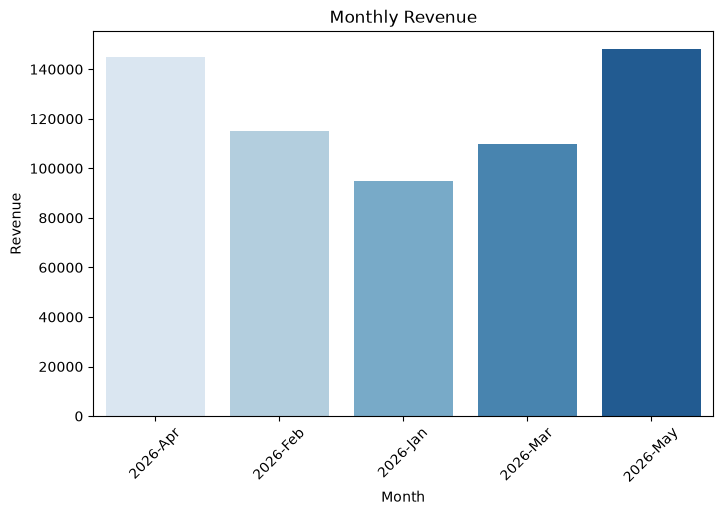

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.barplot(x=monthly_revenue.index, y=monthly_revenue.values, hue=monthly_revenue.index, palette="Blues")
plt.title("Monthly Revenue")
plt.ylabel("Revenue")
plt.xlabel("Month")
plt.xticks(rotation=45)
plt.show()


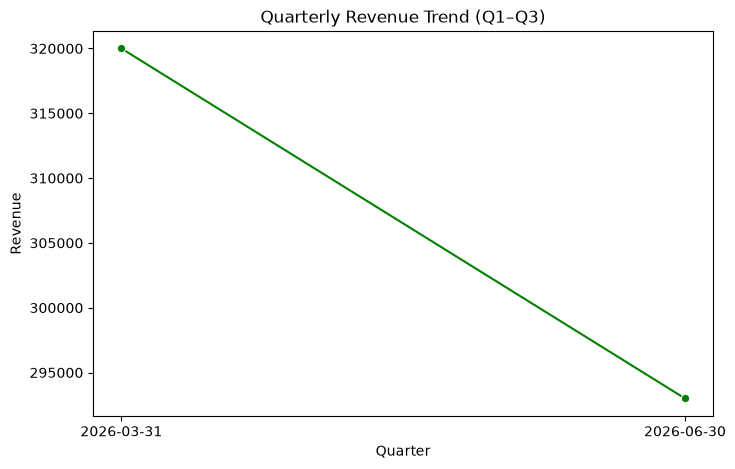

In [84]:
plt.figure(figsize=(8,5))
sns.lineplot(x=quarterly_revenue.index.astype(str), y=quarterly_revenue.values,
             marker="o", color="green")
plt.title("Quarterly Revenue Trend (Q1–Q3)")
plt.ylabel("Revenue")
plt.xlabel("Quarter")
plt.show()


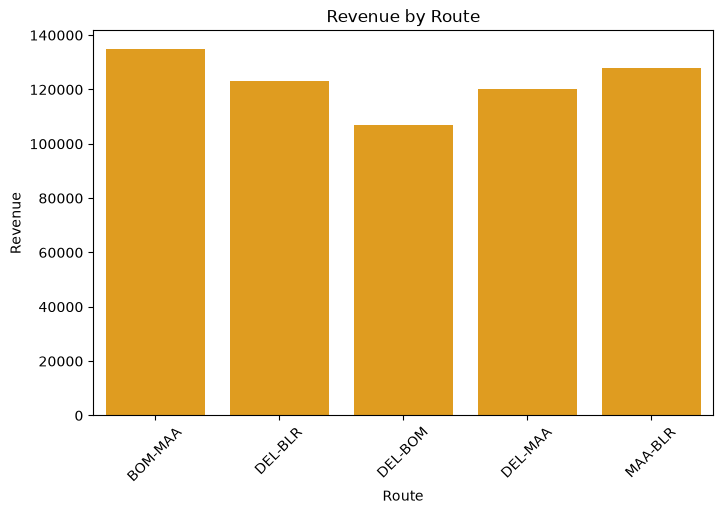

In [87]:
plt.figure(figsize=(8,5))
sns.barplot(x=route_perf.index, y=route_perf["Revenue"], color="orange")
plt.title("Revenue by Route")
plt.ylabel("Revenue")
plt.xlabel("Route")
plt.xticks(rotation=45)
plt.show()


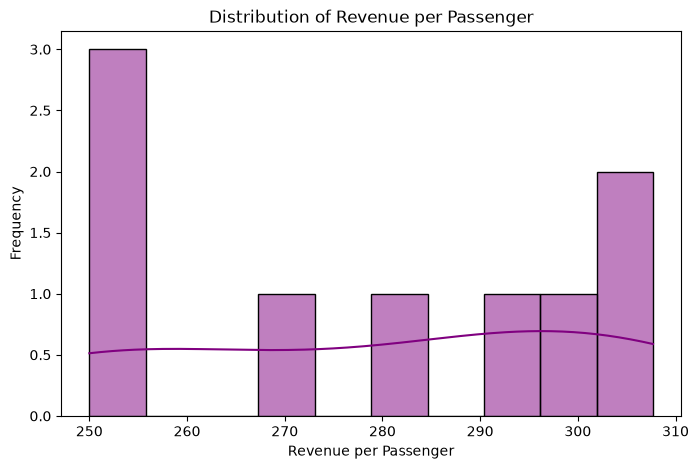

In [67]:
plt.figure(figsize=(8,5))
sns.histplot(df["Revenue_per_Passenger"], bins=10, kde=True, color="purple")
plt.title("Distribution of Revenue per Passenger")
plt.xlabel("Revenue per Passenger")
plt.ylabel("Frequency")
plt.show()


In [98]:
# Group by route and sum revenue
route_perf = df.groupby("Route")["Revenue"].sum()

# Sort routes by revenue (descending)
sorted_routes = route_perf.sort_values(ascending=False)


In [99]:
# Top 3 routes
top_routes = sorted_routes.head(3)

# Lowest 3 routes
lowest_routes = sorted_routes.tail(3)


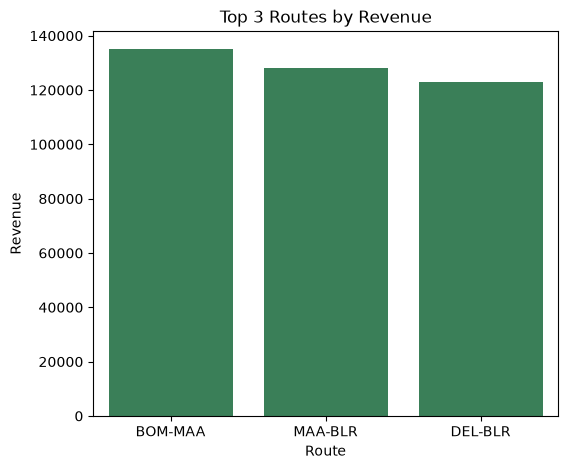

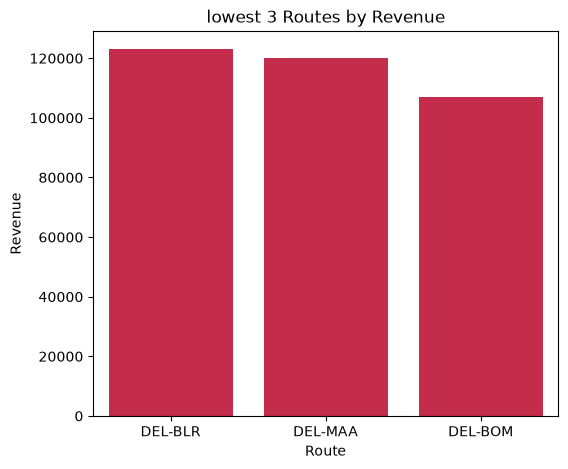

In [104]:
# Top routes
plt.figure(figsize=(6,5))
sns.barplot(x=top_routes.index, y=top_routes.values, color="seagreen")
plt.title("Top 3 Routes by Revenue")
plt.ylabel("Revenue")
plt.xlabel("Route")
plt.show()

# Lowest routes
plt.figure(figsize=(6,5))
sns.barplot(x=lowest_routes.index, y=lowest_routes.values, color="crimson")
plt.title("lowest 3 Routes by Revenue")
plt.ylabel("Revenue")
plt.xlabel("Route")
plt.show()

